In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv", parse_dates=["date"])

print(df.shape)
print(df["date"].min(), "sampai", df["date"].max())
print(f"Jumlah toko: {df['store'].nunique()}, jumlah produk: {df['item'].nunique()}")
df.head()

(913000, 4)
2013-01-01 00:00:00 sampai 2017-12-31 00:00:00
Jumlah toko: 10, jumlah produk: 50


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


### Pola musiman & tren keseluruhan

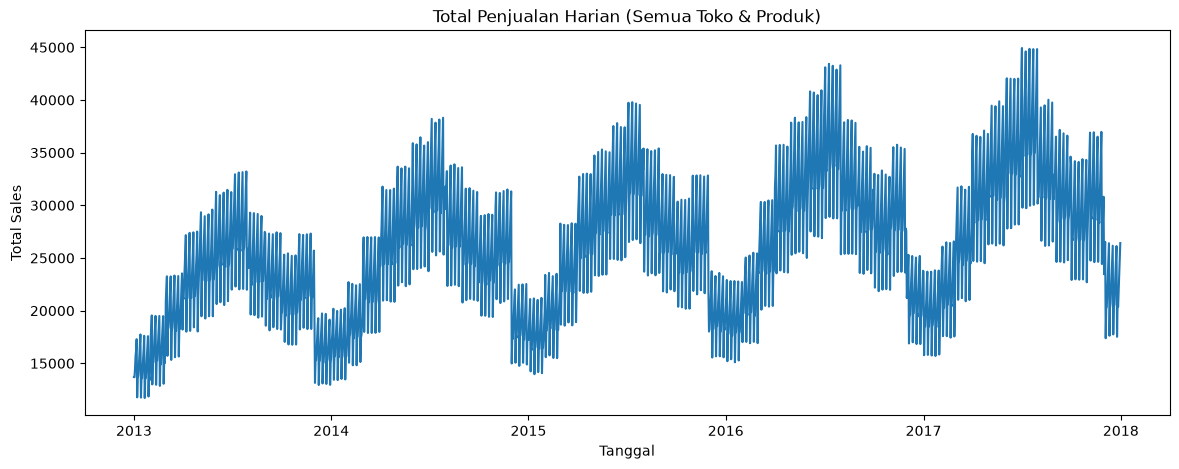

In [2]:
import matplotlib.pyplot as plt

daily_total = df.groupby("date")["sales"].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(daily_total["date"], daily_total["sales"])
plt.title("Total Penjualan Harian (Semua Toko & Produk)")
plt.xlabel("Tanggal")
plt.ylabel("Total Sales")
plt.savefig("../reports/daily_sales_trend.png", dpi=150)
plt.show()

### Pola mingguan

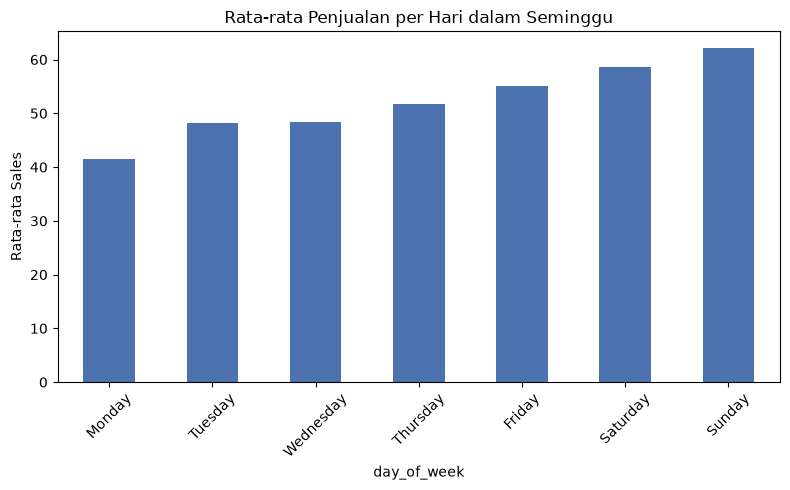

In [3]:
df["day_of_week"] = df["date"].dt.day_name()
weekly_pattern = df.groupby("day_of_week")["sales"].mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)

plt.figure(figsize=(8, 5))
weekly_pattern.plot(kind="bar", color="#4C72B0")
plt.title("Rata-rata Penjualan per Hari dalam Seminggu")
plt.ylabel("Rata-rata Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../reports/weekly_pattern.png", dpi=150)
plt.show()

### Variasi antar toko dan antar produk

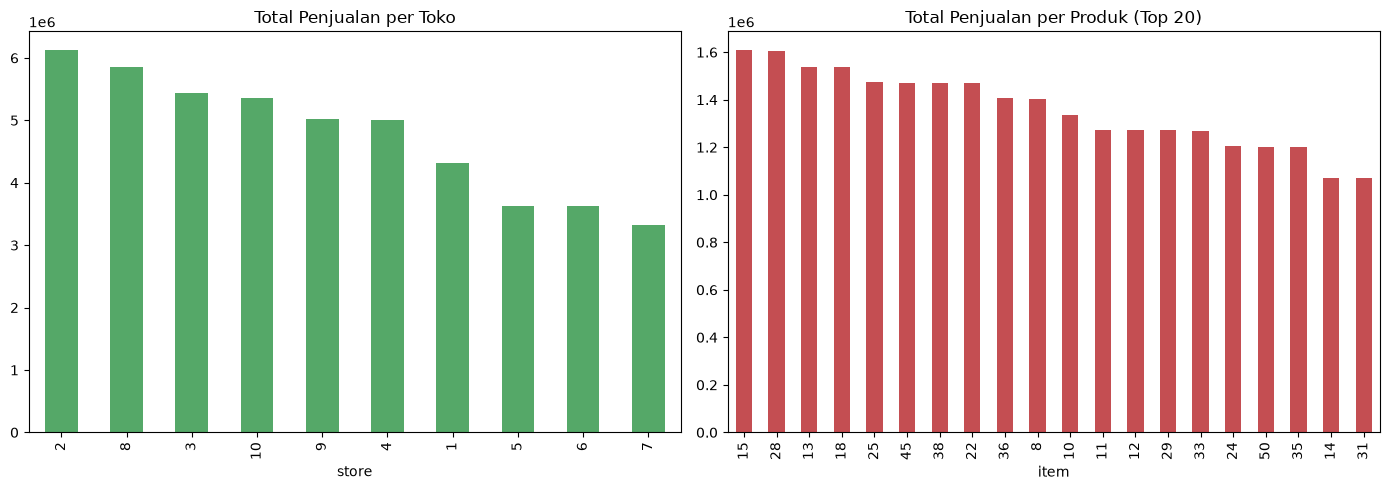

In [4]:
store_totals = df.groupby("store")["sales"].sum().sort_values(ascending=False)
item_totals = df.groupby("item")["sales"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
store_totals.plot(kind="bar", ax=axes[0], color="#55A868")
axes[0].set_title("Total Penjualan per Toko")
item_totals.head(20).plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Total Penjualan per Produk (Top 20)")
plt.tight_layout()
plt.savefig("../reports/store_item_variation.png", dpi=150)
plt.show()

### Cek kelengkapan data atau null

In [5]:
expected_days = (df["date"].max() - df["date"].min()).days + 1
actual_days_per_combo = df.groupby(["store", "item"])["date"].nunique()

print(f"Jumlah hari seharusnya: {expected_days}")
print(f"Kombinasi toko-produk dengan data tidak lengkap: {(actual_days_per_combo != expected_days).sum()}")

Jumlah hari seharusnya: 1826
Kombinasi toko-produk dengan data tidak lengkap: 0
